# OULAD 数据集详细信息整理

**Open University Learning Analytics Dataset (OULAD)** 是英国开放大学（The Open University）发布的真实学习分析数据集，广泛用于学生成绩预测、辍学预警、教育数据挖掘等研究。

- **来源**: [Kuzilek et al., 2017](https://analyse.kmi.open.ac.uk/open_dataset/)
- **时间跨度**: 2013–2014 学年多个学期（J=10月开课，B=2月开课）
- **课程模块**: 7 个匿名模块（AAA–GGG）
- **本 notebook**: 对本地 `OULAD/` 目录下 7 张 CSV 表做结构说明、统计特征、通过率与分数分布及可视化

## 1. 环境与数据路径

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 中文显示（Windows 常用字体）
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="Set2")

DATA_DIR = Path("OULAD")  # 与 notebook 同目录时指向 OULAD 文件夹
assert DATA_DIR.exists(), f"未找到数据目录: {DATA_DIR.resolve()}"

## 2. 数据集总览：七张关联表

| 文件名 | 含义 | 粒度 |
|--------|------|------|
| `courses.csv` | 课程/学期长度 | 模块 × 学期 |
| `studentInfo.csv` | 学生人口统计与**最终结果** | 学生 × 模块 × 学期 |
| `studentRegistration.csv` | 注册/退课日期 | 学生 × 模块 × 学期 |
| `assessments.csv` | 作业/考试元数据 | 评估项 |
| `studentAssessment.csv` | 学生各次评估**分数** | 学生 × 评估项 |
| `vle.csv` | 虚拟学习环境（VLE）资源 | 站点 |
| `studentVle.csv` | 学生对 VLE 的**点击**日志 | 学生 × 站点 × 日期 |

**关联键**: `code_module` + `code_presentation` 连接课程；`id_student` 连接学生；`id_assessment` / `id_site` 连接评估与 VLE。

In [3]:
FILES = {
    "courses": "courses.csv",
    "studentInfo": "studentInfo.csv",
    "studentRegistration": "studentRegistration.csv",
    "assessments": "assessments.csv",
    "studentAssessment": "studentAssessment.csv",
    "vle": "vle.csv",
}

# studentVle 超过千万行，不在此全量读入；仅统计行数
STUDENT_VLE_PATH = DATA_DIR / "studentVle.csv"

def count_csv_rows(path: Path) -> int:
    with path.open("r", encoding="utf-8", errors="replace") as f:
        return sum(1 for _ in f) - 1  # 减去表头

student_vle_nrows = count_csv_rows(STUDENT_VLE_PATH)

dfs = {name: pd.read_csv(DATA_DIR / fname) for name, fname in FILES.items()}

overview_rows = []
for name, df in dfs.items():
    overview_rows.append({
        "表名": name,
        "行数": f"{len(df):,}",
        "列数": len(df.columns),
        "字段": ", ".join(df.columns),
        "内存(MB)": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
    })

overview_rows.append({
    "表名": "studentVle",
    "行数": f"{student_vle_nrows:,}",
    "列数": 6,
    "字段": "code_module, code_presentation, id_student, id_site, date, sum_click",
    "内存(MB)": "— (建议分块读取)",
})

overview_df = pd.DataFrame(overview_rows)
overview_df

,表名,行数,列数,字段,内存(MB)
0,courses,22,3,"code_module, code_presentation, module_present...",0.0
1,studentInfo,"32,593",12,"code_module, code_presentation, id_student, ge...",16.3
2,studentRegistration,"32,593",5,"code_module, code_presentation, id_student, da...",4.04
3,assessments,206,6,"code_module, code_presentation, id_assessment,...",0.04
4,studentAssessment,"173,912",5,"id_assessment, id_student, date_submitted, is_...",6.63
5,vle,"6,364",6,"id_site, code_module, code_presentation, activ...",1.13
6,studentVle,"10,655,280",6,"code_module, code_presentation, id_student, id...",— (建议分块读取)


### 2.1 各表字段说明与样例

In [4]:
SCHEMA_DOC = {
    "courses": {
        "code_module": "模块代码 (AAA–GGG)",
        "code_presentation": "学期代码，如 2013J（2013年10月）、2014B（2014年2月）",
        "module_presentation_length": "学期总天数（用于将 date 转为相对天）",
    },
    "studentInfo": {
        "gender": "性别 M/F",
        "region": "英国地区",
        "highest_education": "入学前最高学历",
        "imd_band": "英格兰多重剥夺指数分档（苏格兰等地区可能为空）",
        "age_band": "年龄区间",
        "num_of_prev_attempts": "该模块此前尝试次数",
        "studied_credits": "本学期修读学分",
        "disability": "是否申报残疾 Y/N",
        "final_result": "最终结果: Distinction / Pass / Fail / Withdrawn",
    },
    "studentRegistration": {
        "date_registration": "注册日（相对学期第0天，可为负=提前注册）",
        "date_unregistration": "退课日，空表示未退课",
    },
    "assessments": {
        "assessment_type": "TMA(导师评分作业) / CMA(计算机评分) / Exam",
        "date": "截止/考试日（相对天，Exam 常为空）",
        "weight": "该评估在模块总成绩中的权重百分比",
    },
    "studentAssessment": {
        "date_submitted": "提交日（相对天）",
        "is_banked": "是否沿用以往尝试分数 (0/1)",
        "score": "得分，通常 0–100",
    },
    "vle": {
        "activity_type": "资源类型: resource, oucontent, url, forumng, quiz 等",
        "week_from / week_to": "资源开放周（可为空）",
    },
    "studentVle": {
        "date": "点击发生日（相对天）",
        "sum_click": "当日该站点点击次数",
    },
}

for name, df in dfs.items():
    print(f"\n{'='*60}\n【{name}】  dtypes:\n{df.dtypes}\n")
    if name in SCHEMA_DOC:
        for col, desc in SCHEMA_DOC[name].items():
            if col in df.columns:
                print(f"  · {col}: {desc}")
        display(df.head(3))

print(f"\n{'='*60}\n【studentVle】 行数约 {student_vle_nrows:,}（未全量加载）")
for col, desc in SCHEMA_DOC["studentVle"].items():
    print(f"  · {col}: {desc}")
display(pd.read_csv(STUDENT_VLE_PATH, nrows=3))


【courses】  dtypes:
code_module                   object
code_presentation             object
module_presentation_length     int64
dtype: object

  · code_module: 模块代码 (AAA–GGG)
  · code_presentation: 学期代码，如 2013J（2013年10月）、2014B（2014年2月）
  · module_presentation_length: 学期总天数（用于将 date 转为相对天）


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268



【studentInfo】  dtypes:
code_module             object
code_presentation       object
id_student               int64
gender                  object
region                  object
highest_education       object
imd_band                object
age_band                object
num_of_prev_attempts     int64
studied_credits          int64
disability              object
final_result            object
dtype: object

  · gender: 性别 M/F
  · region: 英国地区
  · highest_education: 入学前最高学历
  · imd_band: 英格兰多重剥夺指数分档（苏格兰等地区可能为空）
  · age_band: 年龄区间
  · num_of_prev_attempts: 该模块此前尝试次数
  · studied_credits: 本学期修读学分
  · disability: 是否申报残疾 Y/N
  · final_result: 最终结果: Distinction / Pass / Fail / Withdrawn


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn



【studentRegistration】  dtypes:
code_module             object
code_presentation       object
id_student               int64
date_registration      float64
date_unregistration    float64
dtype: object

  · date_registration: 注册日（相对学期第0天，可为负=提前注册）
  · date_unregistration: 退课日，空表示未退课


...

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78.0
1,1752,28400,22,0,70.0
2,1752,31604,17,0,72.0



【vle】  dtypes:
id_site                int64
code_module           object
code_presentation     object
activity_type         object
week_from            float64
week_to              float64
dtype: object

  · activity_type: 资源类型: resource, oucontent, url, forumng, quiz 等


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,NaN,NaN
1,546712,AAA,2013J,oucontent,NaN,NaN
2,546998,AAA,2013J,resource,NaN,NaN



【studentVle】 行数约 10,655,280（未全量加载）
  · date: 点击发生日（相对天）
  · sum_click: 当日该站点点击次数


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1


## 3. 课程与学期结构

In [5]:
courses = dfs["courses"]
si = dfs["studentInfo"]

print(f"模块数: {courses['code_module'].nunique()}  →  {sorted(courses['code_module'].unique())}")
print(f"模块-学期组合数: {len(courses)}")
print(f"学期长度(天): min={courses['module_presentation_length'].min()}, "
      f"max={courses['module_presentation_length'].max()}, "
      f"mean={courses['module_presentation_length'].mean():.1f}")

course_students = (
    si.groupby(["code_module", "code_presentation"])
    .size()
    .reset_index(name="学生人次")
    .merge(courses, on=["code_module", "code_presentation"])
)
course_students

模块数: 7  →  ['AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF', 'GGG']
模块-学期组合数: 22
学期长度(天): min=234, max=269, mean=255.5


,code_module,code_presentation,学生人次,module_presentation_length
0,AAA,2013J,383,268
1,AAA,2014J,365,269
2,BBB,2013B,1767,240
3,BBB,2013J,2237,268
4,BBB,2014B,1613,234
5,BBB,2014J,2292,262
6,CCC,2014B,1936,241
7,CCC,2014J,2498,269
8,DDD,2013B,1303,240
9,DDD,2013J,1938,261


C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2666854093.py:12: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2666854093.py:12: UserWarning: Glyph 22359 (\N{CJK UNIFIED IDEOGRAPH-5757}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2666854093.py:12: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2666854093.py:12: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2666854093.py:12: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2666854093.py:12: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21})

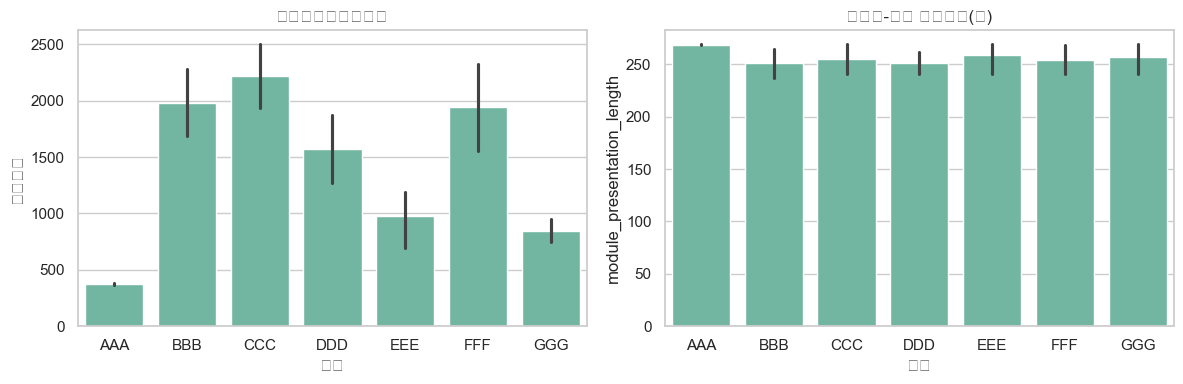

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=course_students, x="code_module", y="学生人次", ax=axes[0])
axes[0].set_title("各模块注册学生人次")
axes[0].set_xlabel("模块")
axes[0].tick_params(axis="x", rotation=0)

sns.barplot(data=course_students, x="code_module", y="module_presentation_length", ax=axes[1])
axes[1].set_title("各模块-学期 学期长度(天)")
axes[1].set_xlabel("模块")

plt.tight_layout()
plt.show()

## 4. 学生样本与人口统计特征

每条 `studentInfo` 记录表示一名学生在**某一模块某一学期**上的一条修读记录（同一学生可有多条记录）。

In [7]:
print(f"修读记录总数: {len(si):,}")
print(f"独立学生 id_student: {si['id_student'].nunique():,}")
print(f"人均修读模块-学期数: {len(si) / si['id_student'].nunique():.2f}")

demo_cols = ["gender", "region", "highest_education", "imd_band", "age_band", "disability"]
for col in demo_cols:
    n_miss = (si[col].astype(str).str.strip() == "").sum() if si[col].dtype == object else si[col].isna().sum()
    print(f"\n【{col}】 缺失/空: {n_miss}  唯一值数: {si[col].nunique()}")
    print(si[col].value_counts(dropna=False).head(8))

修读记录总数: 32,593
独立学生 id_student: 28,785
人均修读模块-学期数: 1.13

【gender】 缺失/空: 0  唯一值数: 2
gender
M    17875
F    14718
Name: count, dtype: int64

【region】 缺失/空: 0  唯一值数: 13
region
Scotland                3446
East Anglian Region     3340
London Region           3216
South Region            3092
North Western Region    2906
West Midlands Region    2582
South West Region       2436
East Midlands Region    2365
Name: count, dtype: int64

【highest_education】 缺失/空: 0  唯一值数: 5
highest_education
A Level or Equivalent          14045
Lower Than A Level             13158
HE Qualification                4730
No Formal quals                  347
Post Graduate Qualification      313
Name: count, dtype: int64

【imd_band】 缺失/空: 0  唯一值数: 10
imd_band
20-30%    3654
30-40%    3539
10-20     3516
0-10%     3311
40-50%    3256
50-60%    3124
60-70%    2905
70-80%    2879
Name: count, dtype: int64

【age_band】 缺失/空: 0  唯一值数: 3
age_band
0-35     22944
35-55     9433
55<=       216
Name: count, dtype: int64

【disabi

C:\Users\20108\AppData\Local\Temp\ipykernel_18088\769649729.py:24: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\769649729.py:24: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\769649729.py:24: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\769649729.py:24: UserWarning: Glyph 21035 (\N{CJK UNIFIED IDEOGRAPH-522B}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\769649729.py:24: UserWarning: Glyph 24180 (\N{CJK UNIFIED IDEOGRAPH-5E74}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\769649729.py:24: UserWarning: Glyph 40836 (\N{CJK UNIFIED IDEOGRAPH-9F84}) missi

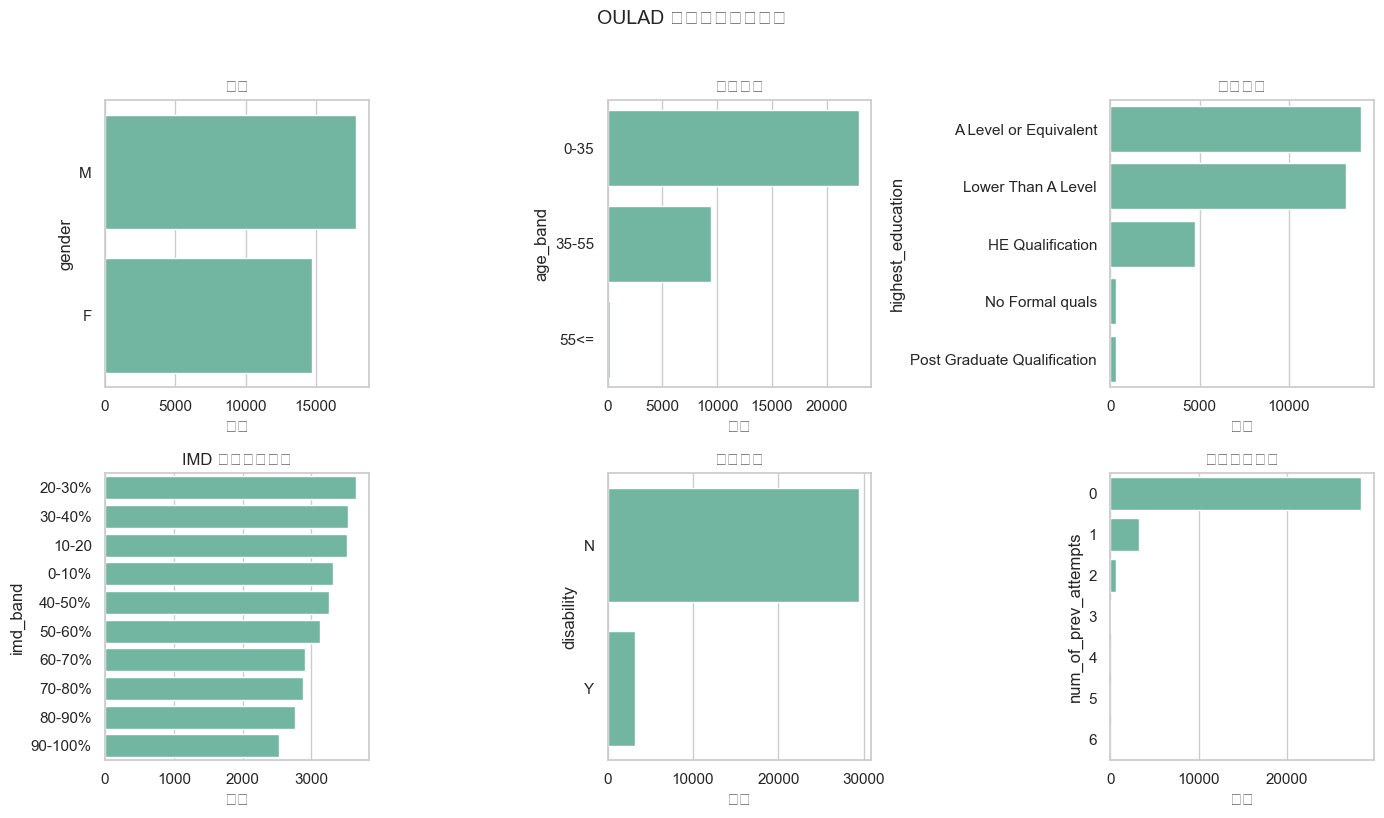

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

plot_cols = [
    ("gender", "性别"),
    ("age_band", "年龄区间"),
    ("highest_education", "最高学历"),
    ("imd_band", "IMD 剥夺指数分档"),
    ("disability", "残疾申报"),
    ("num_of_prev_attempts", "此前尝试次数"),
]

for ax, (col, title) in zip(axes, plot_cols):
  vc = si[col].value_counts()
  if col == "highest_education":
    vc = vc.head(8)
  if col == "imd_band":
    vc = vc[vc.index.astype(str).str.strip() != ""]
  sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, orient="h")
  ax.set_title(title)
  ax.set_xlabel("人数")

plt.suptitle("OULAD 人口统计特征分布", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20462 (\N{CJK UNIFIED IDEOGRAPH-4FEE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 35835 (\N{CJK UNIFIED IDEOGRAPH-8BFB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph

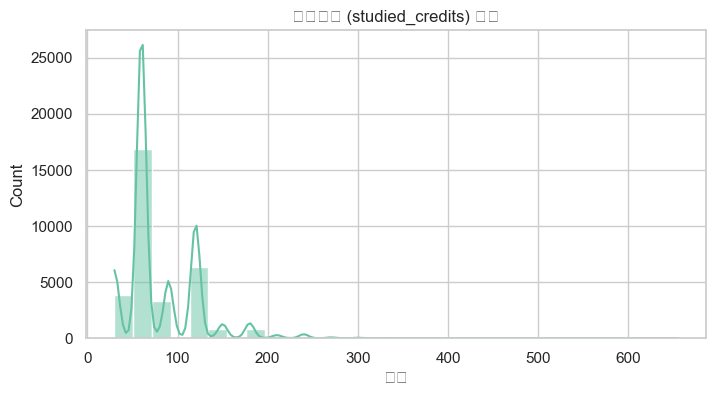

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(si["studied_credits"], bins=30, kde=True, ax=ax)
ax.set_title("修读学分 (studied_credits) 分布")
ax.set_xlabel("学分")
plt.show()

## 5. 最终结果与通过率

`final_result` 四类标签：
- **Distinction**: 优秀通过
- **Pass**: 通过
- **Fail**: 未通过（完成但未达标）
- **Withdrawn**: 退学/未完成

研究中常将 Pass+Distinction 视为“通过”，或将 Fail+Withdrawn 视为负面结果用于二分类预测。

In [10]:
RESULT_ORDER = ["Distinction", "Pass", "Fail", "Withdrawn"]
RESULT_COLORS = {"Distinction": "#2ecc71", "Pass": "#3498db", "Fail": "#e74c3c", "Withdrawn": "#95a5a6"}

result_counts = si["final_result"].value_counts().reindex(RESULT_ORDER)
result_pct = (result_counts / len(si) * 100).round(2)

summary_result = pd.DataFrame({"人数": result_counts, "占比(%)": result_pct})
summary_result["累计占比(%)"] = result_pct.cumsum()

pass_rate = (si["final_result"].isin(["Pass", "Distinction"])).mean()
distinction_rate = (si["final_result"] == "Distinction").mean()
withdrawn_rate = (si["final_result"] == "Withdrawn").mean()
fail_rate = (si["final_result"] == "Fail").mean()

print(f"通过+优秀 通过率: {pass_rate:.2%}")
print(f"优秀率 (Distinction): {distinction_rate:.2%}")
print(f"不及格率 (Fail): {fail_rate:.2%}")
print(f"退学率 (Withdrawn): {withdrawn_rate:.2%}")
summary_result

通过+优秀 通过率: 47.20%
优秀率 (Distinction): 9.28%
不及格率 (Fail): 21.64%
退学率 (Withdrawn): 31.16%


,人数,占比(%),累计占比(%)
final_result,,,
Distinction,3024,9.28,9.28
Pass,12361,37.93,47.21
Fail,7052,21.64,68.85
Withdrawn,10156,31.16,100.01


C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2044724167.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=si, x="final_result", order=RESULT_ORDER, palette=[RESULT_COLORS[r] for r in RESULT_ORDER], ax=axes[1])
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2044724167.py:16: UserWarning: Glyph 26368 (\N{CJK UNIFIED IDEOGRAPH-6700}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2044724167.py:16: UserWarning: Glyph 32456 (\N{CJK UNIFIED IDEOGRAPH-7EC8}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2044724167.py:16: UserWarning: Glyph 32467 (\N{CJK UNIFIED IDEOGRAPH-7ED3}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2044724167.py:16: UserWarning: Glyph 26524 (\N{CJ

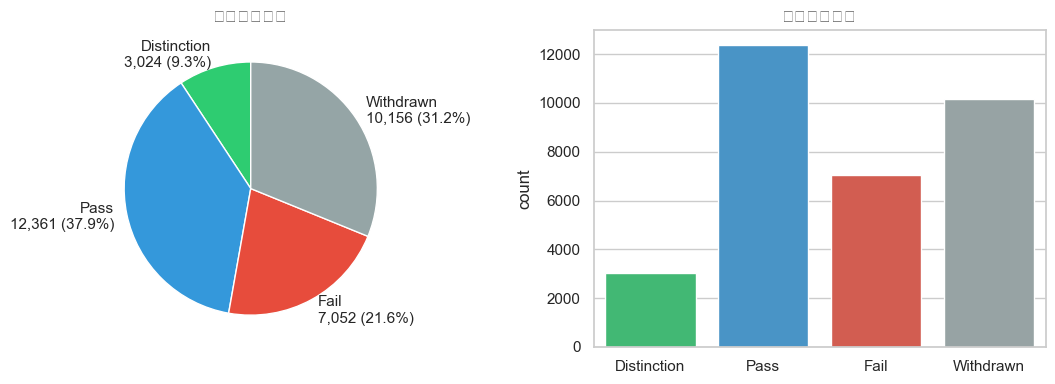

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].pie(
    result_counts,
    labels=[f"{k}\n{v:,} ({result_pct[k]:.1f}%)" for k, v in result_counts.items()],
    colors=[RESULT_COLORS[k] for k in RESULT_ORDER],
    autopct="",
    startangle=90,
)
axes[0].set_title("最终结果分布")

sns.countplot(data=si, x="final_result", order=RESULT_ORDER, palette=[RESULT_COLORS[r] for r in RESULT_ORDER], ax=axes[1])
axes[1].set_title("最终结果计数")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

In [12]:
def pass_rate_series(df, group_cols):
    g = df.groupby(group_cols, observed=True)
    passed = g["final_result"].apply(lambda s: s.isin(["Pass", "Distinction"]).mean())
    n = g.size()
    out = pd.DataFrame({"人数": n, "通过率": passed})
    return out.sort_values("通过率", ascending=False)

by_module = pass_rate_series(si, "code_module")
by_gender = pass_rate_series(si, "gender")
by_edu = pass_rate_series(si, "highest_education")
by_age = pass_rate_series(si, "age_band")
by_attempts = pass_rate_series(si, "num_of_prev_attempts")

print("按模块通过率:")
display(by_module)
print("\n按此前尝试次数:")
display(by_attempts)

按模块通过率:


,人数,通过率
code_module,,
AAA,748,0.709893
GGG,2534,0.597474
EEE,2934,0.562372
BBB,7909,0.474649
FFF,7762,0.469982
DDD,6272,0.416135
CCC,4434,0.378439



按此前尝试次数:


,人数,通过率
num_of_prev_attempts,,
0,28421,0.492769
1,3299,0.345559
4,39,0.333333
2,675,0.284444
6,4,0.250000
3,142,0.225352
5,13,0.153846


C:\Users\20108\AppData\Local\Temp\ipykernel_18088\3446525227.py:24: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\3446525227.py:24: UserWarning: Glyph 36807 (\N{CJK UNIFIED IDEOGRAPH-8FC7}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\3446525227.py:24: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\3446525227.py:24: UserWarning: Glyph 21508 (\N{CJK UNIFIED IDEOGRAPH-5404}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\3446525227.py:24: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\3446525227.py:24: UserWarning: Glyph 22359 (\N{CJK UNIFIED IDEOGRAPH-5757})

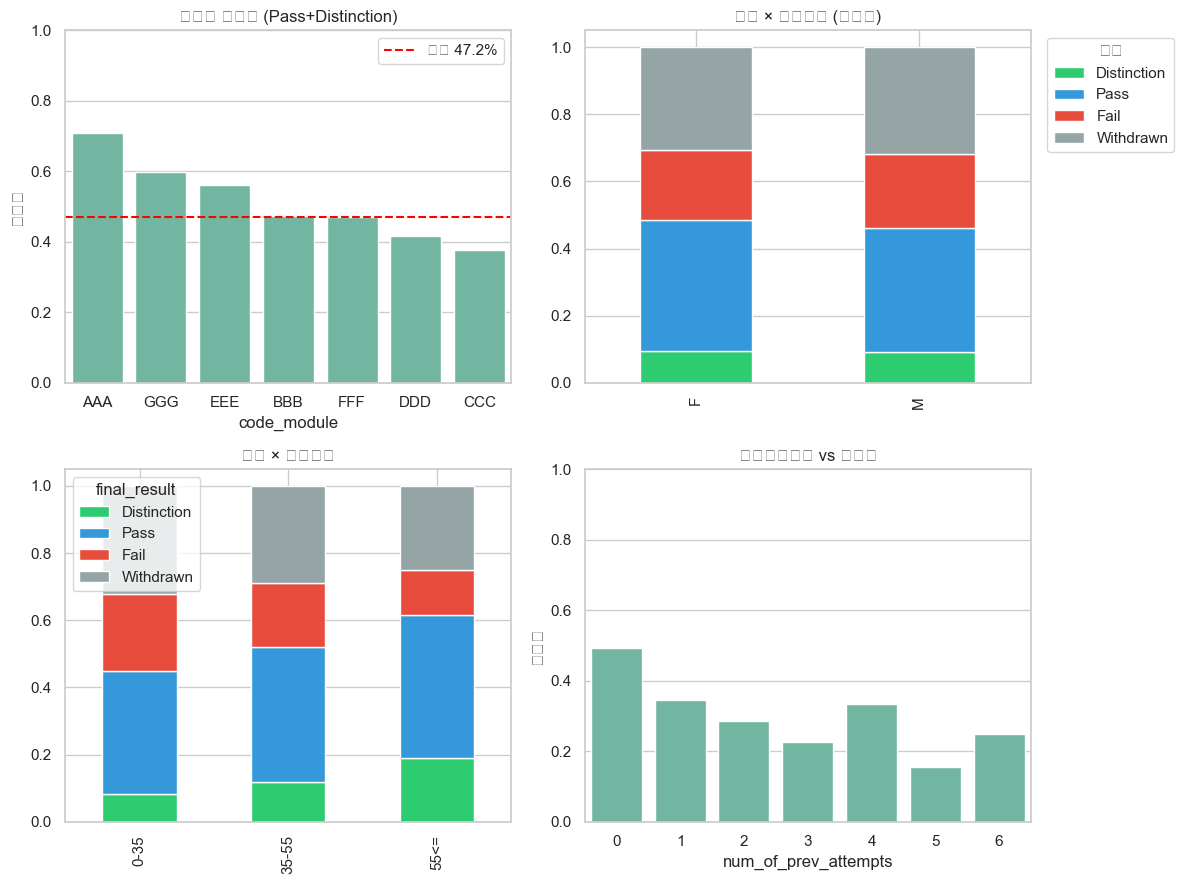

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.barplot(data=by_module.reset_index(), x="code_module", y="通过率", ax=axes[0, 0])
axes[0, 0].set_title("各模块 通过率 (Pass+Distinction)")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].axhline(pass_rate, color="red", ls="--", label=f"总体 {pass_rate:.1%}")
axes[0, 0].legend()

ct = pd.crosstab(si["gender"], si["final_result"], normalize="index")[RESULT_ORDER]
ct.plot(kind="bar", stacked=True, ax=axes[0, 1], color=[RESULT_COLORS[r] for r in RESULT_ORDER])
axes[0, 1].set_title("性别 × 最终结果 (行比例)")
axes[0, 1].set_xlabel("")
axes[0, 1].legend(title="结果", bbox_to_anchor=(1.02, 1))

ct2 = pd.crosstab(si["age_band"], si["final_result"], normalize="index")[RESULT_ORDER]
ct2.plot(kind="bar", stacked=True, ax=axes[1, 0], color=[RESULT_COLORS[r] for r in RESULT_ORDER])
axes[1, 0].set_title("年龄 × 最终结果")
axes[1, 0].set_xlabel("")

sns.barplot(data=by_attempts.reset_index(), x="num_of_prev_attempts", y="通过率", ax=axes[1, 1])
axes[1, 1].set_title("此前尝试次数 vs 通过率")
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 6. 评估（Assessment）与分数

- **TMA**: Tutor Marked Assignment，导师评分作业，通常占模块成绩一部分
- **CMA**: Computer Marked Assignment，自动评分小测验（部分模块）
- **Exam**: 期末考试，权重常为 100%（与 TMA 权重在 assessments 表中分别列出，需按模块理解评分规则）

In [14]:
assess = dfs["assessments"]
sa = dfs["studentAssessment"]

print("评估项总数:", len(assess))
print("\n评估类型分布:")
print(assess["assessment_type"].value_counts())
print("\n各类型权重示例 (前5):")
display(assess.groupby("assessment_type")["weight"].describe())

print(f"\n学生-评估提交记录: {len(sa):,}")
print(f"有分数的记录: {sa['score'].notna().sum():,}")
print(f"score 范围: [{sa['score'].min():.0f}, {sa['score'].max():.0f}]")
print(f"is_banked=1 比例: {(sa['is_banked']==1).mean():.2%}")

评估项总数: 206

评估类型分布:
assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64

各类型权重示例 (前5):


,count,mean,std,min,25%,50%,75%,max
assessment_type,,,,,,,,
CMA,76.0,1.184211,2.219372,0.0,0.0,0.0,1.0,8.0
Exam,24.0,100.000000,0.000000,100.0,100.0,100.0,100.0,100.0
TMA,106.0,17.075472,8.524975,0.0,12.5,18.0,25.0,35.0



学生-评估提交记录: 173,912
有分数的记录: 173,739
score 范围: [0, 100]
is_banked=1 比例: 1.10%


In [15]:
sa_merged = sa.merge(
    assess[["id_assessment", "code_module", "code_presentation", "assessment_type", "weight"]],
    on="id_assessment",
    how="left",
)

score_by_type = sa_merged.groupby("assessment_type")["score"].agg(["count", "mean", "std", "median", "min", "max"]).round(2)
score_by_type

,count,mean,std,median,min,max
assessment_type,,,,,,
CMA,70527,81.03,17.84,82.0,0.0,100.0
Exam,4959,65.57,20.58,67.0,0.0,100.0
TMA,98253,72.56,18.43,76.0,0.0,100.0


C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2842992689.py:10: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2842992689.py:10: UserWarning: Glyph 37096 (\N{CJK UNIFIED IDEOGRAPH-90E8}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2842992689.py:10: UserWarning: Glyph 35780 (\N{CJK UNIFIED IDEOGRAPH-8BC4}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2842992689.py:10: UserWarning: Glyph 20272 (\N{CJK UNIFIED IDEOGRAPH-4F30}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2842992689.py:10: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\2842992689.py:10: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570})

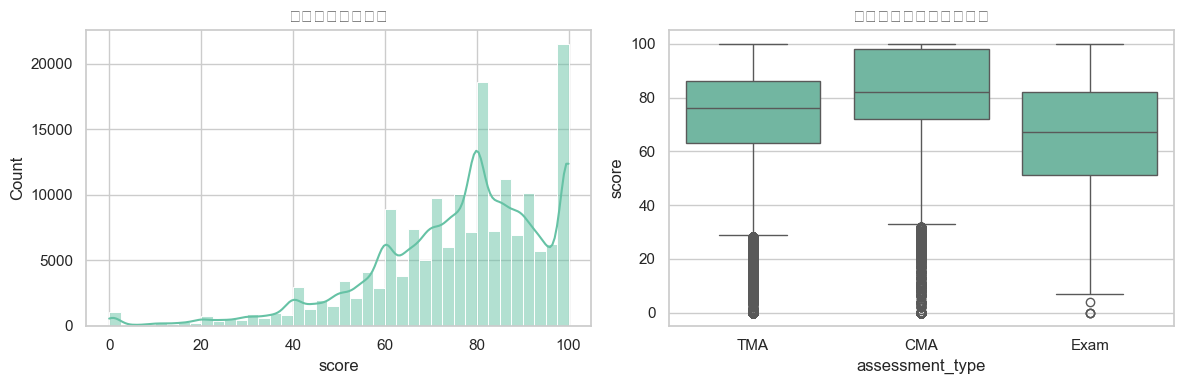

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(sa_merged["score"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("全部评估分数分布")
axes[0].set_xlabel("score")

sns.boxplot(data=sa_merged, x="assessment_type", y="score", order=["TMA", "CMA", "Exam"], ax=axes[1])
axes[1].set_title("按评估类型的分数箱线图")

plt.tight_layout()
plt.show()

C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21508 (\N{CJK UNIFIED IDEOGRAPH-5404}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 35780 (\N{CJK UNIFIED IDEOGRAPH-8BC4}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20272 (\N{CJK UNIFIED IDEOGRAPH-4F30}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph

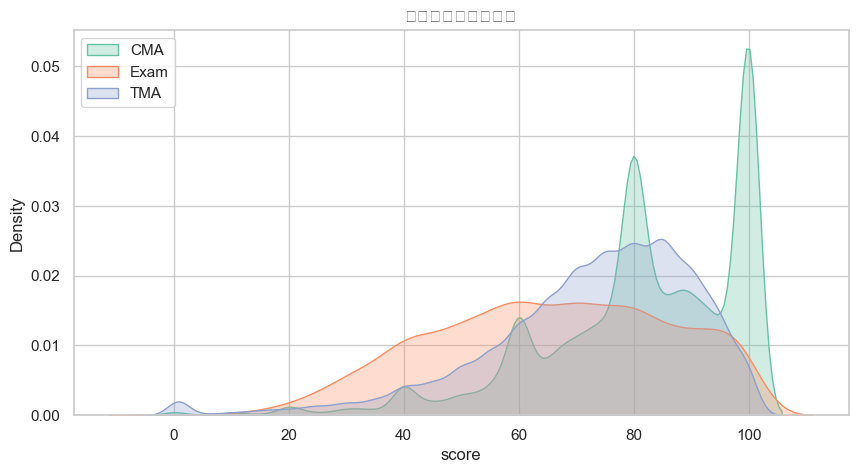

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
for atype, sub in sa_merged.groupby("assessment_type"):
    sns.kdeplot(sub["score"], label=atype, ax=ax, fill=True, alpha=0.3)
ax.set_title("各评估类型分数密度")
ax.set_xlabel("score")
ax.legend()
plt.show()

C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1926257931.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=si_scores, x="final_result", y="tma_mean_score", order=RESULT_ORDER,
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, *

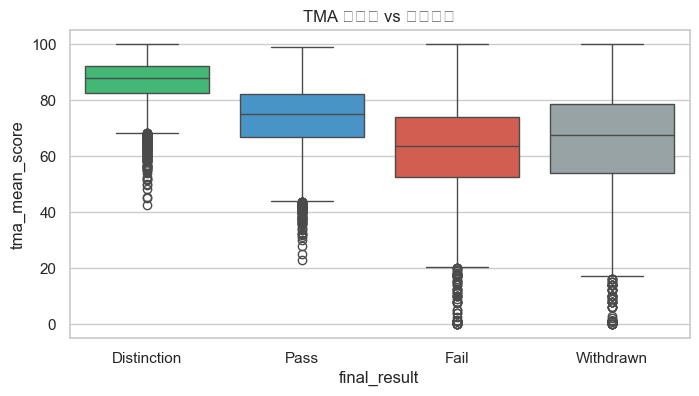

In [18]:
# 每条修读记录：TMA 平均分 vs 最终结果
tma_avg = (
    sa_merged[sa_merged["assessment_type"] == "TMA"]
        .groupby(["id_student", "code_module", "code_presentation"])["score"]
    .mean()
    .rename("tma_mean_score")
)

si_scores = si.merge(tma_avg, on=["id_student", "code_module", "code_presentation"], how="left")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=si_scores, x="final_result", y="tma_mean_score", order=RESULT_ORDER,
            palette=[RESULT_COLORS[r] for r in RESULT_ORDER], ax=ax)
ax.set_title("TMA 平均分 vs 最终结果")
plt.show()

C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1459407424.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(weighted_score)
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1459407424.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=si_w.dropna(subset=["weighted_mean_score"]), x="final_result", y="weighted_mean_score",
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26435 (\N{CJK UNIFIED IDEOGRAPH-6743}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io,

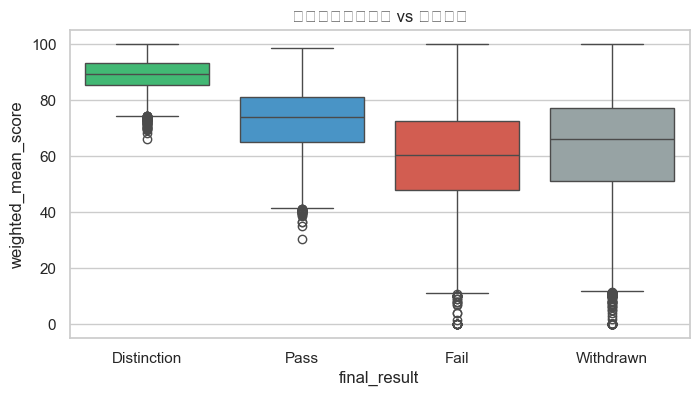

,count,mean,std,min,25%,50%,75%,max
final_result,,,,,,,,
Distinction,2628.0,88.95,5.77,66.15,85.50,89.25,93.04,100.00
Fail,5193.0,59.78,17.01,0.00,47.78,60.25,72.42,100.00
Pass,11240.0,72.52,11.26,30.27,65.08,73.75,81.00,98.68
Withdrawn,4423.0,62.73,19.93,0.00,51.00,66.00,77.13,100.00


In [19]:
# 加权平均成绩（按 assessments.weight）— 仅对有分数且权重大于0的项
def weighted_score(group):
    w = group["weight"].fillna(0)
    s = group["score"]
    mask = s.notna() & (w > 0)
    if mask.sum() == 0 or w[mask].sum() == 0:
        return np.nan
    return np.average(s[mask], weights=w[mask])

student_weighted = (
    sa_merged.groupby(["id_student", "code_module", "code_presentation"], group_keys=False)
    .apply(weighted_score)
    .rename("weighted_mean_score")
    .reset_index()
)

si_w = si.merge(student_weighted, on=["id_student", "code_module", "code_presentation"], how="left")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=si_w.dropna(subset=["weighted_mean_score"]), x="final_result", y="weighted_mean_score",
            order=RESULT_ORDER, palette=[RESULT_COLORS[r] for r in RESULT_ORDER], ax=ax)
ax.set_title("权重加权平均成绩 vs 最终结果")
plt.show()

si_w.groupby("final_result")["weighted_mean_score"].describe().round(2)

## 7. 注册与退学时间

In [20]:
reg = dfs["studentRegistration"].copy()
reg["date_unregistration"] = pd.to_numeric(reg["date_unregistration"], errors="coerce")
reg["unregistered"] = reg["date_unregistration"].notna()

print(f"注册记录数: {len(reg):,}")
print(f"有退课日期比例: {reg['unregistered'].mean():.2%}")
print(f"\n注册日 date_registration 分位数:")
print(reg["date_registration"].describe())

withdrawn_days = reg.loc[reg["unregistered"], "date_unregistration"]
print(f"\n退课日分位数 (仅已退课):")
print(withdrawn_days.describe())

注册记录数: 32,593
有退课日期比例: 30.90%

注册日 date_registration 分位数:
count    32548.000000
mean       -69.411300
std         49.260522
min       -322.000000
25%       -100.000000
50%        -57.000000
75%        -29.000000
max        167.000000
Name: date_registration, dtype: float64

退课日分位数 (仅已退课):
count    10072.000000
mean        49.757645
std         82.460890
min       -365.000000
25%         -2.000000
50%         27.000000
75%        109.000000
max        444.000000
Name: date_unregistration, dtype: float64


C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1563511981.py:11: UserWarning: Glyph 27880 (\N{CJK UNIFIED IDEOGRAPH-6CE8}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1563511981.py:11: UserWarning: Glyph 20876 (\N{CJK UNIFIED IDEOGRAPH-518C}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1563511981.py:11: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1563511981.py:11: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1563511981.py:11: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\1563511981.py:11: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8})

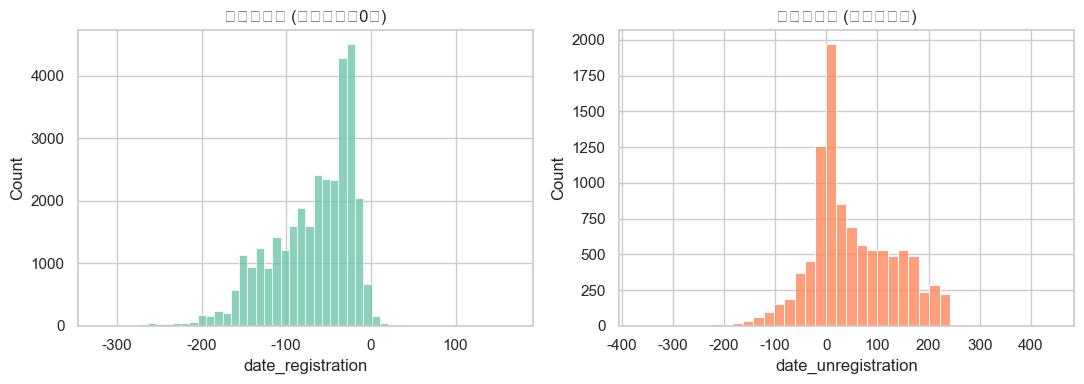

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(reg["date_registration"], bins=50, ax=axes[0])
axes[0].set_title("注册日分布 (相对学期第0天)")
axes[0].set_xlabel("date_registration")

sns.histplot(withdrawn_days, bins=40, ax=axes[1], color="coral")
axes[1].set_title("退课日分布 (已退课学生)")
axes[1].set_xlabel("date_unregistration")

plt.tight_layout()
plt.show()

## 8. VLE 在线学习行为（抽样分析）

`studentVle.csv` 体积最大（千万级行），全量加载耗时且占内存。下面使用**聚合统计**与**随机抽样**展示点击行为特征。

C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 31449 (\N{CJK UNIFIED IDEOGRAPH-7AD9}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 36164 (\N{CJK UNIFIED IDEOGRAPH-8D44}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\20108\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph

VLE 站点数: 6,364

activity_type 分布:
activity_type
resource          2660
subpage           1055
oucontent          996
url                886
forumng            194
quiz               127
page               102
oucollaborate       82
questionnaire       61
ouwiki              49
dataplus            28
externalquiz        26
homepage            22
glossary            21
ouelluminate        21
dualpane            20
repeatactivity       5
htmlactivity         4
sharedsubpage        3
folder               2
Name: count, dtype: int64


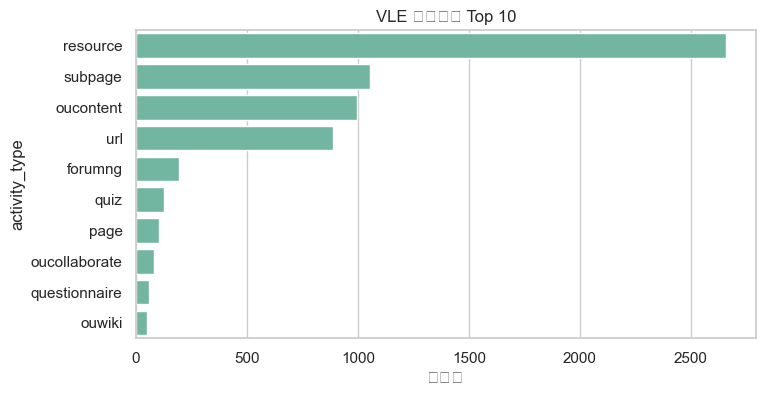

In [22]:
vle = dfs["vle"]
print(f"VLE 站点数: {len(vle):,}")
print("\nactivity_type 分布:")
print(vle["activity_type"].value_counts())

fig, ax = plt.subplots(figsize=(8, 4))
vc = vle["activity_type"].value_counts().head(10)
sns.barplot(x=vc.values, y=vc.index, ax=ax, orient="h")
ax.set_title("VLE 资源类型 Top 10")
ax.set_xlabel("站点数")
plt.show()

In [23]:
# 分块读取 studentVle，聚合到学生-模块-学期级别总点击
USE_FULL_VLE = False  # 改为 True 可全量聚合（需足够内存与时间）
SAMPLE_NROWS = 2_000_000  # 抽样行数用于快速探索

if USE_FULL_VLE:
    chunks = []
    for chunk in pd.read_csv(DATA_DIR / "studentVle.csv", chunksize=500_000):
        g = chunk.groupby(["id_student", "code_module", "code_presentation"])["sum_click"].sum()
        chunks.append(g)
    clicks_per_student = pd.concat(chunks).groupby(level=[0, 1, 2]).sum().reset_index(name="total_clicks")
else:
    sv_sample = pd.read_csv(DATA_DIR / "studentVle.csv", nrows=SAMPLE_NROWS)
    clicks_per_student = (
        sv_sample.groupby(["id_student", "code_module", "code_presentation"])["sum_click"]
        .sum()
        .reset_index(name="total_clicks")
    )
    print(f"[抽样] 读取前 {SAMPLE_NROWS:,} 行 → {len(clicks_per_student):,} 个学生-课程组合")

clicks_per_student["total_clicks"].describe()

[抽样] 读取前 2,000,000 行 → 8,996 个学生-课程组合


count     8996.000000
mean       754.575923
std       1193.037848
min          1.000000
25%        122.000000
50%        375.000000
75%        919.000000
max      16440.000000
Name: total_clicks, dtype: float64

C:\Users\20108\AppData\Local\Temp\ipykernel_18088\580522799.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=si_clicks, x="final_result", y="total_clicks", order=RESULT_ORDER,
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\580522799.py:15: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\580522799.py:15: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\580522799.py:15: UserWarning: Glyph 20987 (\N{CJK UNIFIED IDEOGRAPH-51FB}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\20108\AppData\Local\Temp\ipykernel_18088\580522799.py:15: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21}) missing from font

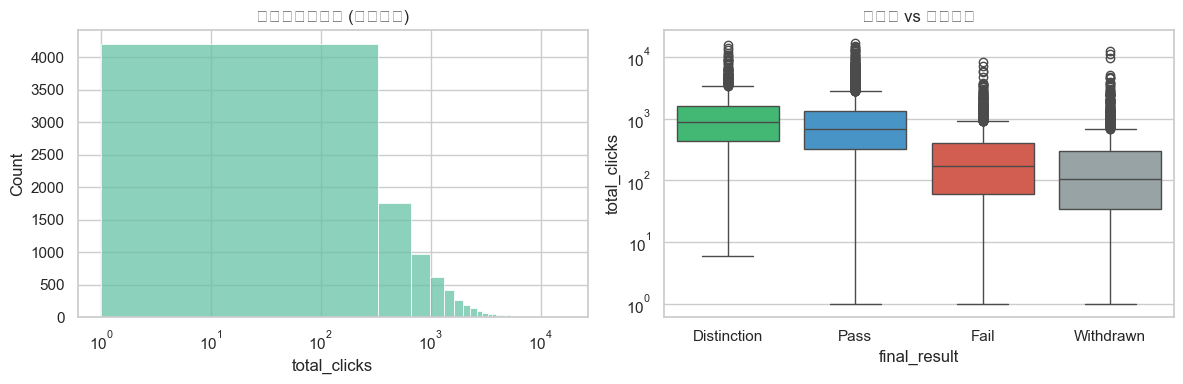

final_result
Distinction    880.0
Fail           173.0
Pass           670.0
Withdrawn      104.0
Name: total_clicks, dtype: float64

In [24]:
si_clicks = si.merge(clicks_per_student, on=["id_student", "code_module", "code_presentation"], how="inner")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(si_clicks["total_clicks"], bins=50, ax=axes[0])
axes[0].set_title("总点击次数分布 (对数坐标)")
axes[0].set_xscale("log")
axes[0].set_xlabel("total_clicks")

sns.boxplot(data=si_clicks, x="final_result", y="total_clicks", order=RESULT_ORDER,
            palette=[RESULT_COLORS[r] for r in RESULT_ORDER], ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("总点击 vs 最终结果")

plt.tight_layout()
plt.show()

si_clicks.groupby("final_result")["total_clicks"].median()

## 9. 关键特征小结（建模常用）

| 类别 | 字段 | 说明 |
|------|------|------|
| 标签 | `final_result` | 四分类；二分类时常用 Pass+Distinction vs 其余 |
| 人口统计 | gender, region, highest_education, imd_band, age_band, disability | 类别特征；注意 imd_band 缺失 |
| 学业背景 | num_of_prev_attempts, studied_credits | 数值/有序；重考次数与通过率负相关 |
| 行为 | studentVle 聚合点击、活跃天数、资源类型计数 | 需从日志聚合 |
| 成绩 | studentAssessment.score | TMA/CMA/Exam；可算均值、加权分、提交及时性 |
| 时间 | date_registration, date_unregistration, date_submitted | 相对学期天数 |

In [25]:
KEY_STATS = {
    "修读记录数": len(si),
    "独立学生数": si["id_student"].nunique(),
    "模块数": si["code_module"].nunique(),
    "模块-学期组合": len(courses),
    "通过+优秀率": f"{pass_rate:.2%}",
    "退学率": f"{withdrawn_rate:.2%}",
    "评估提交记录": len(sa),
    "VLE站点数": len(vle),
    "studentVle行数(文件)": f"{student_vle_nrows:,}",
}

pd.Series(KEY_STATS, name="OULAD 关键统计")

修读记录数                    32593
独立学生数                    28785
模块数                          7
模块-学期组合                     22
通过+优秀率                  47.20%
退学率                     31.16%
评估提交记录                  173912
VLE站点数                    6364
studentVle行数(文件)    10,655,280
Name: OULAD 关键统计, dtype: object

## 10. 参考文献

> Jakub Kuzilek, Hana Koprinska, Drahomira Herrmannova, Zdenek Zdrahal, Christoph Hillaire, René Assche (2017). **Open University Learning Analytics dataset**. Scientific Data.

官方说明与数据字典: https://analyse.kmi.open.ac.uk/open_dataset/